# 实验四 C CNN LSTM 中文图像描述生成

使用要求指定的 [cross lingual cap](https://github.com/li-xirong/cross-lingual-cap) 项目所列的 [COCO CN](https://github.com/li-xirong/coco-cn)，从作者发布的 [Hugging Face 标注包](https://huggingface.co/datasets/AIMClab/COCO-CN) 读取人工中文描述，图片来自 COCO 官方服务器。为适合本机 CPU，从官方训练、验证、测试清单分别随机取 3000、300、300 张图，随机种子 42；保持官方图像划分，同图全部描述归属同一集合。

编码器为 ImageNet 预训练 ResNet18，冻结权重；解码器为本实验从随机初始化训练的字符级 LSTM。没有使用现成图像描述模型或翻译模型。评价为中文字符级 BLEU 与 ROUGE L，不能直接与论文的分词级指标比较。

In [1]:
from pathlib import Path
import random, json, copy, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset

ROOT = Path.cwd() if (Path.cwd() / "exp4").is_dir() else Path.cwd().parent
BASE = ROOT / "exp4"
DATA = BASE / "data"
CACHE = BASE / ".cache" / "exp4C"
RESULT = BASE / "results" / "exp4C"
for folder in [DATA, CACHE, RESULT]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
                     "axes.unicode_minus": False, "figure.dpi": 110})
print("Python:", sys.executable, "设备:", device)

Python: D:\Anaconda\python.exe 设备: cpu


## 1 数据下载与官方划分

In [2]:
import requests, tarfile, hashlib, re
from concurrent.futures import ThreadPoolExecutor
from collections import Counter
from PIL import Image
from torchvision import models, transforms
from nltk.translate.bleu_score import corpus_bleu
from torch.nn.utils.rnn import pad_sequence

def download(url, path):
    path = Path(path)
    if path.exists() and path.stat().st_size > 0:
        return
    path.parent.mkdir(parents=True, exist_ok=True)
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            tmp = path.with_suffix(path.suffix + '.download')
            tmp.write_bytes(r.content)
            tmp.replace(path)
            return
        except Exception:
            if attempt == 3:
                raise
            time.sleep(1)


archive_path=BASE/".cache/coco-cn.tar.gz"
download("https://huggingface.co/datasets/AIMClab/COCO-CN/resolve/main/coco-cn-version1805v1.1.tar.gz",archive_path)
def caption_data():
    with tarfile.open(BASE / '.cache/coco-cn.tar.gz') as archive:
        prefix = 'coco-cn-version1805v1.1/'
        captions = {}
        for line in archive.extractfile(prefix + 'imageid.human-written-caption.txt').read().decode().splitlines():
            key, text = line.split(None, 1)
            captions.setdefault(key.split('#')[0], []).append(text.strip())
        rows = []
        for split, count in [('train', 3000), ('val', 300), ('test', 300)]:
            ids = archive.extractfile(prefix + f'coco-cn_{split}.txt').read().decode().splitlines()
            ids = sorted(set(ids) & captions.keys())
            random.Random(SEED).shuffle(ids)
            for key in ids[:count]:
                folder = key.split('_')[1]
                rows.append(dict(image_id=key, split=split, captions=captions[key],
                                 url=f'http://images.cocodataset.org/{folder}/{key}.jpg'))
    def one(row):
        path = DATA / 'coco_cn/images' / (row['image_id'] + '.jpg')
        try:
            download(row['url'], path)
            with Image.open(path) as im:
                im.verify()
            return row
        except Exception as e:
            print('FAILED', row['image_id'], str(e)[:150], flush=True)
            return None
    done = []
    with ThreadPoolExecutor(16) as executor:
        for i, row in enumerate(executor.map(one, rows), 1):
            if row: done.append(row)
            if i % 300 == 0: print('CAPTION', i, '/', len(rows), flush=True)
    (DATA / 'coco_cn/manifest.json').write_text(json.dumps(done, ensure_ascii=False, indent=2), encoding='utf-8')
    print('CAPTION READY', pd.Series([r['split'] for r in done]).value_counts().to_dict(), flush=True)


manifest_path=DATA/"coco_cn/manifest.json"
if not manifest_path.exists():caption_data()
rows=json.loads(manifest_path.read_text(encoding="utf-8"))
df=pd.DataFrame(rows)
assert df.image_id.is_unique
assert df.groupby("split").size().to_dict()=={"test":300,"train":3000,"val":300}, "下载未完整，请检查失败记录"
df[["image_id","split","url"]].to_csv(RESULT/"image_split.csv",index=False)
display(df.groupby("split").agg(images=("image_id","count"),captions=("captions",lambda x:sum(map(len,x)))))

,images,captions
split,,
test,300,315
train,3000,3283
val,300,327


## 2 ResNet 图像特征

图像转换 RGB，将整图缩放至 224×224，不裁剪；长宽比可能改变，展示仍使用原图。采用 ImageNet 均值与标准差归一化。ResNet18 去掉 1000 类分类层，取全局平均池化后的 512 维向量。编码器始终 eval 且不计算梯度，特征只缓存确定性编码结果。

权重为 [torchvision ResNet18 IMAGENET1K V1](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)，可复用 exp3 缓存；若没有则从 PyTorch 官方下载。

In [3]:
transform=transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])])
weight_path=ROOT/"exp3/.cache/torch/checkpoints/resnet18-f37072fd.pth"
encoder=models.resnet18(weights=None)
if weight_path.exists():
    encoder.load_state_dict(torch.load(weight_path,map_location="cpu",weights_only=True))
else:
    state=torch.hub.load_state_dict_from_url("https://download.pytorch.org/models/resnet18-f37072fd.pth",model_dir=str(BASE/".cache/torch/checkpoints"),check_hash=True,map_location="cpu")
    encoder.load_state_dict(state)
encoder.fc=nn.Identity();encoder.to(device).eval()
for p in encoder.parameters():p.requires_grad=False

class ImageDataset(Dataset):
    def __len__(self):return len(df)
    def __getitem__(self,i):
        with Image.open(DATA/"coco_cn/images"/(df.iloc[i].image_id+".jpg")) as im:
            return transform(im.convert("RGB"))

fingerprint=hashlib.sha256("\n".join(df.image_id).encode()).hexdigest()[:16]
feature_path=CACHE/f"resnet18_resize224_{fingerprint}.pt"
if feature_path.exists():features=torch.load(feature_path,weights_only=True)
else:
    pieces=[]
    with torch.no_grad():
        for i,x in enumerate(DataLoader(ImageDataset(),batch_size=32,num_workers=0)):
            pieces.append(encoder(x.to(device)).cpu())
            if i%20==0:print("特征提取",min((i+1)*32,len(df)),"/",len(df),flush=True)
    features=torch.cat(pieces)
    torch.save(features,feature_path)
assert features.shape==(len(df),512)
print("特征形状",features.shape)
del encoder

特征提取 32 / 3600


特征提取 672 / 3600


特征提取 1312 / 3600


特征提取 1952 / 3600


特征提取 2592 / 3600


特征提取 3232 / 3600


特征形状 torch.Size([3600, 512])


## 3 字符词表与 LSTM 解码器

清除空白，统一中英文标点，保留汉字、数字和拉丁字母。仅用训练描述建立至少出现两次的字符词表，特殊符号为 PAD、BOS、EOS、UNK。最多 40 个字符，保留结尾 EOS。Embedding=128，LSTM 隐藏单元=256，一层；图像向量分别投影为初始 h 与 c。训练输入 BOS 加参考前文，目标为参考文本加 EOS，使用 teacher forcing 和忽略 PAD 的交叉熵。推理从 BOS 开始贪心生成，遇 EOS 结束。

Adam 学习率 0.002、batch=64、最多 35 轮，梯度裁剪 1，验证交叉熵连续 6 轮不下降时停止。用最低验证损失选权重，测试集只在训练完成后评估。

CaptionDecoder(
  (embedding): Embedding(1169, 128, padding_idx=0)
  (initial_h): Linear(in_features=512, out_features=256, bias=True)
  (initial_c): Linear(in_features=512, out_features=256, bias=True)
  (lstm): LSTM(128, 256, batch_first=True)
  (output): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=256, out_features=1169, bias=True)
  )
)
可训练参数 1107985 词表 1169


epoch 1 train 5.1324 val 4.3281


epoch 2 train 3.9501 val 3.6714


epoch 3 train 3.4331 val 3.355


epoch 4 train 3.133 val 3.1521


epoch 5 train 2.916 val 3.0221


... (14 outputs left out)

epoch 20 train 1.6913 val 2.6658


epoch 21 train 1.646 val 2.6899


epoch 22 train 1.6027 val 2.6806


epoch 23 train 1.5521 val 2.6869


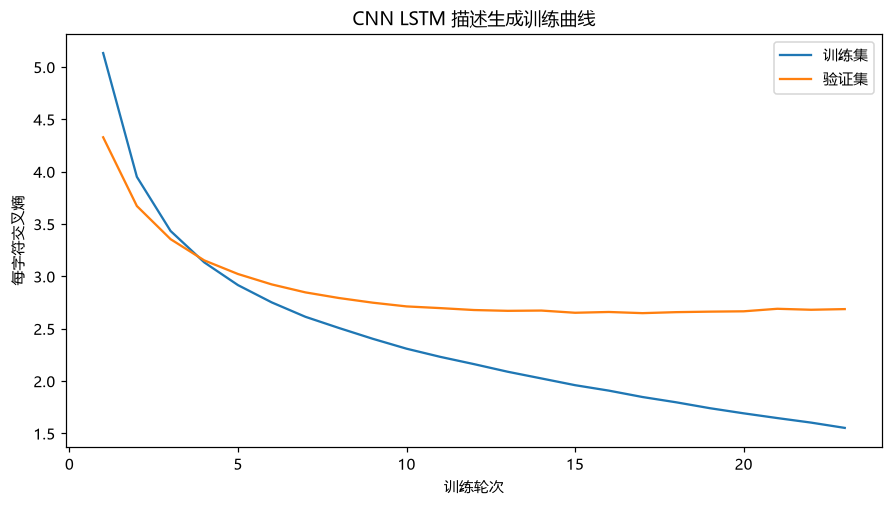

In [4]:
def clean(text):
    return re.sub(r"[^\u4e00-\u9fffA-Za-z0-9]","",text).lower()
references=[[clean(text) for text in row.captions if clean(text)] for row in df.itertuples()]
counter=Counter("".join(text for i in df.index[df.split=="train"] for text in references[i]))
itos=["<pad>","<bos>","<eos>","<unk>"]+sorted(c for c,n in counter.items() if n>=2)
stoi={s:i for i,s in enumerate(itos)}
MAX_LEN=40
pairs={s:[] for s in ["train","val","test"]}
for i in range(len(df)):
    for text in references[i]:
        ids=[1]+[stoi.get(c,3) for c in text[:MAX_LEN]]+[2]
        pairs[df.loc[i,"split"]].append((i,torch.tensor(ids,dtype=torch.long)))

def collate_caption(batch):
    ids,seqs=zip(*batch)
    seq=pad_sequence(seqs,batch_first=True,padding_value=0)
    return features[list(ids)],seq[:,:-1],seq[:,1:]
loaders={s:DataLoader(p,batch_size=64,shuffle=s=="train",collate_fn=collate_caption,num_workers=0,generator=torch.Generator().manual_seed(SEED)) for s,p in pairs.items()}

class CaptionDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding=nn.Embedding(len(itos),128,padding_idx=0)
        self.initial_h=nn.Linear(512,256);self.initial_c=nn.Linear(512,256)
        self.lstm=nn.LSTM(128,256,batch_first=True)
        self.output=nn.Sequential(nn.Dropout(0.3),nn.Linear(256,len(itos)))
    def initial_state(self,image_features):
        return self.initial_h(image_features).tanh().unsqueeze(0),self.initial_c(image_features).tanh().unsqueeze(0)
    def forward(self,image_features,tokens):
        hidden,_=self.lstm(self.embedding(tokens),self.initial_state(image_features))
        return self.output(hidden)
    @torch.no_grad()
    def generate(self,image_features):
        self.eval();state=self.initial_state(image_features)
        token=torch.ones((len(image_features),1),dtype=torch.long,device=device)
        sequences=[[] for _ in range(len(image_features))];finished=torch.zeros(len(image_features),dtype=torch.bool,device=device)
        for _ in range(MAX_LEN+1):
            hidden,state=self.lstm(self.embedding(token),state)
            logits=self.output(hidden[:,-1]);logits[:,[0,1,3]]=-1e9
            token=logits.argmax(1,keepdim=True)
            for i,t in enumerate(token[:,0].tolist()):
                if not finished[i] and t!=2:sequences[i].append(itos[t])
            finished|=token[:,0]==2
            if finished.all():break
        return ["".join(s) for s in sequences]

torch.manual_seed(SEED)
model=CaptionDecoder().to(device)
print(model);print("可训练参数",sum(p.numel() for p in model.parameters()),"词表",len(itos))
optimizer=torch.optim.Adam(model.parameters(),lr=0.002,weight_decay=1e-5)
criterion=nn.CrossEntropyLoss(ignore_index=0,reduction="sum")
def epoch_caption(loader,training=False):
    model.train(training);loss_sum=0;count=0
    with torch.set_grad_enabled(training):
        for f,x,y in loader:
            f,x,y=f.to(device),x.to(device),y.to(device)
            logits=model(f,x);loss=criterion(logits.reshape(-1,len(itos)),y.reshape(-1));n=(y!=0).sum()
            if training:
                optimizer.zero_grad();(loss/n).backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
            loss_sum+=loss.item();count+=n.item()
    return loss_sum/count

best,stale,state,best_epoch=float("inf"),0,None,0
history=[]
for epoch in range(1,36):
    train_loss=epoch_caption(loaders["train"],True);val_loss=epoch_caption(loaders["val"])
    history.append(dict(epoch=epoch,train_loss=train_loss,val_loss=val_loss))
    print("epoch",epoch,"train",round(train_loss,4),"val",round(val_loss,4),flush=True)
    if val_loss<best-1e-4:best,stale,state,best_epoch=val_loss,0,copy.deepcopy(model.state_dict()),epoch
    else:stale+=1
    if stale>=6:break
model.load_state_dict(state);torch.save(state,CACHE/"caption_lstm_best.pth")
(CACHE/"vocab.json").write_text(json.dumps(stoi,ensure_ascii=False),encoding="utf-8")
history_df=pd.DataFrame(history);history_df.to_csv(RESULT/"training_history.csv",index=False)
fig,ax=plt.subplots(figsize=(8,4.5),constrained_layout=True)
ax.plot(history_df.epoch,history_df.train_loss,label="训练集");ax.plot(history_df.epoch,history_df.val_loss,label="验证集")
ax.set(title="CNN LSTM 描述生成训练曲线",xlabel="训练轮次",ylabel="每字符交叉熵");ax.legend()
fig.savefig(RESULT/"training_curves.png",dpi=180);plt.show()

## 4 独立测试与图像特征打乱对照

BLEU 使用每张图的全部人工描述作参考，按字符计算语料级 BLEU1～4，不做平滑。ROUGE L 用最长公共子序列的 F1，每张图取多参考中的最高分后平均。空文本得零。额外将测试图像特征循环错配一个位置，仍对原参考文本评价，用于观察模型是否依赖图像。错配对照只在测试中实施，不用于选模型。

In [5]:
test_ids=df.index[df.split=="test"].to_numpy()
def generate_ids(ids):
    texts=[]
    for start in range(0,len(ids),64):texts.extend(model.generate(features[ids[start:start+64]].to(device)))
    return texts
generated=generate_ids(test_ids)
shuffled=generate_ids(np.roll(test_ids,1))
test_refs=[references[i] for i in test_ids]
def rouge_l(pred,ref):
    if not pred or not ref:return 0.0
    previous=[0]*(len(ref)+1)
    for a in pred:
        current=[0]
        for j,b in enumerate(ref,1):current.append(previous[j-1]+1 if a==b else max(previous[j],current[-1]))
        previous=current
    lcs=previous[-1]
    return 2*lcs/(len(pred)+len(ref))
def evaluate_captions(preds):
    refs=[[list(t) for t in rs] for rs in test_refs]
    hyps=[list(t) for t in preds]
    result={f"BLEU-{n}":corpus_bleu(refs,hyps,weights=tuple([1/n]*n)) for n in range(1,5)}
    result["ROUGE-L"]=np.mean([max(rouge_l(p,r) for r in rs) for p,rs in zip(preds,test_refs)])
    return result
scores=[dict(condition="正确图像",**evaluate_captions(generated)),dict(condition="错配图像",**evaluate_captions(shuffled))]
metric_df=pd.DataFrame(scores);metric_df["test_images"]=len(test_ids);metric_df["best_epoch"]=best_epoch
metric_df.to_csv(RESULT/"metrics.csv",index=False,encoding="utf-8-sig")
predictions=pd.DataFrame({"image_id":df.loc[test_ids,"image_id"].to_numpy(),"generated":generated,"shuffled_generated":shuffled,"references":[json.dumps(r,ensure_ascii=False) for r in test_refs]})
predictions.to_csv(RESULT/"test_predictions.csv",index=False,encoding="utf-8-sig")
display(metric_df.round(4));display(predictions.head(6))
print("贪心输出不同句子数",len(set(generated)),"/",len(generated),"；测试字符交叉熵",epoch_caption(loaders["test"]))

C:\Users\Shiro\AppData\Local\Temp\ipykernel_77672\3440129439.py:4: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  for start in range(0,len(ids),64):texts.extend(model.generate(features[ids[start:start+64]].to(device)))


,condition,BLEU-1,BLEU-2,BLEU-3,BLEU-4,ROUGE-L,test_images,best_epoch
0,正确图像,0.3055,0.1971,0.1278,0.0849,0.3016,300,17
1,错配图像,0.1894,0.0951,0.0479,0.0262,0.1802,300,17


,image_id,generated,shuffled_generated,references
0,COCO_val2014_000000276585,一辆红色的公交车停在一辆汽车旁边,一群人在草地上放风筝,"[""一辆白色的公交车停靠在路边""]"
1,COCO_train2014_000000501299,一个男人在街道上玩滑板,一辆红色的公交车停在一辆汽车旁边,"[""一个穿西装打领带戴墨镜的男人在街上用手机打电话的黑白照片""]"
2,COCO_val2014_000000426376,一个人在海上冲浪,一个男人在街道上玩滑板,"[""一个人踩着滑雪板滑下雪坡""]"
3,COCO_val2014_000000474215,一个人在湖上划船,一个人在海上冲浪,"[""一架飞机飞过海边的楼房""]"
4,COCO_train2014_000000026263,桌子上放着一个白色的盘子上放着一个小孩子和一个小孩子,一个人在湖上划船,"[""一个人左手拿着一只写着字的黄色的香蕉""]"
5,COCO_train2014_000000473420,一个古老的建筑物前有一个巨大的钟表,桌子上放着一个白色的盘子上放着一个小孩子和一个小孩子,"[""一群小鸟停在红绿灯上""]"


贪心输出不同句子数 121 / 300 ；测试字符交叉熵 2.6190300947637715


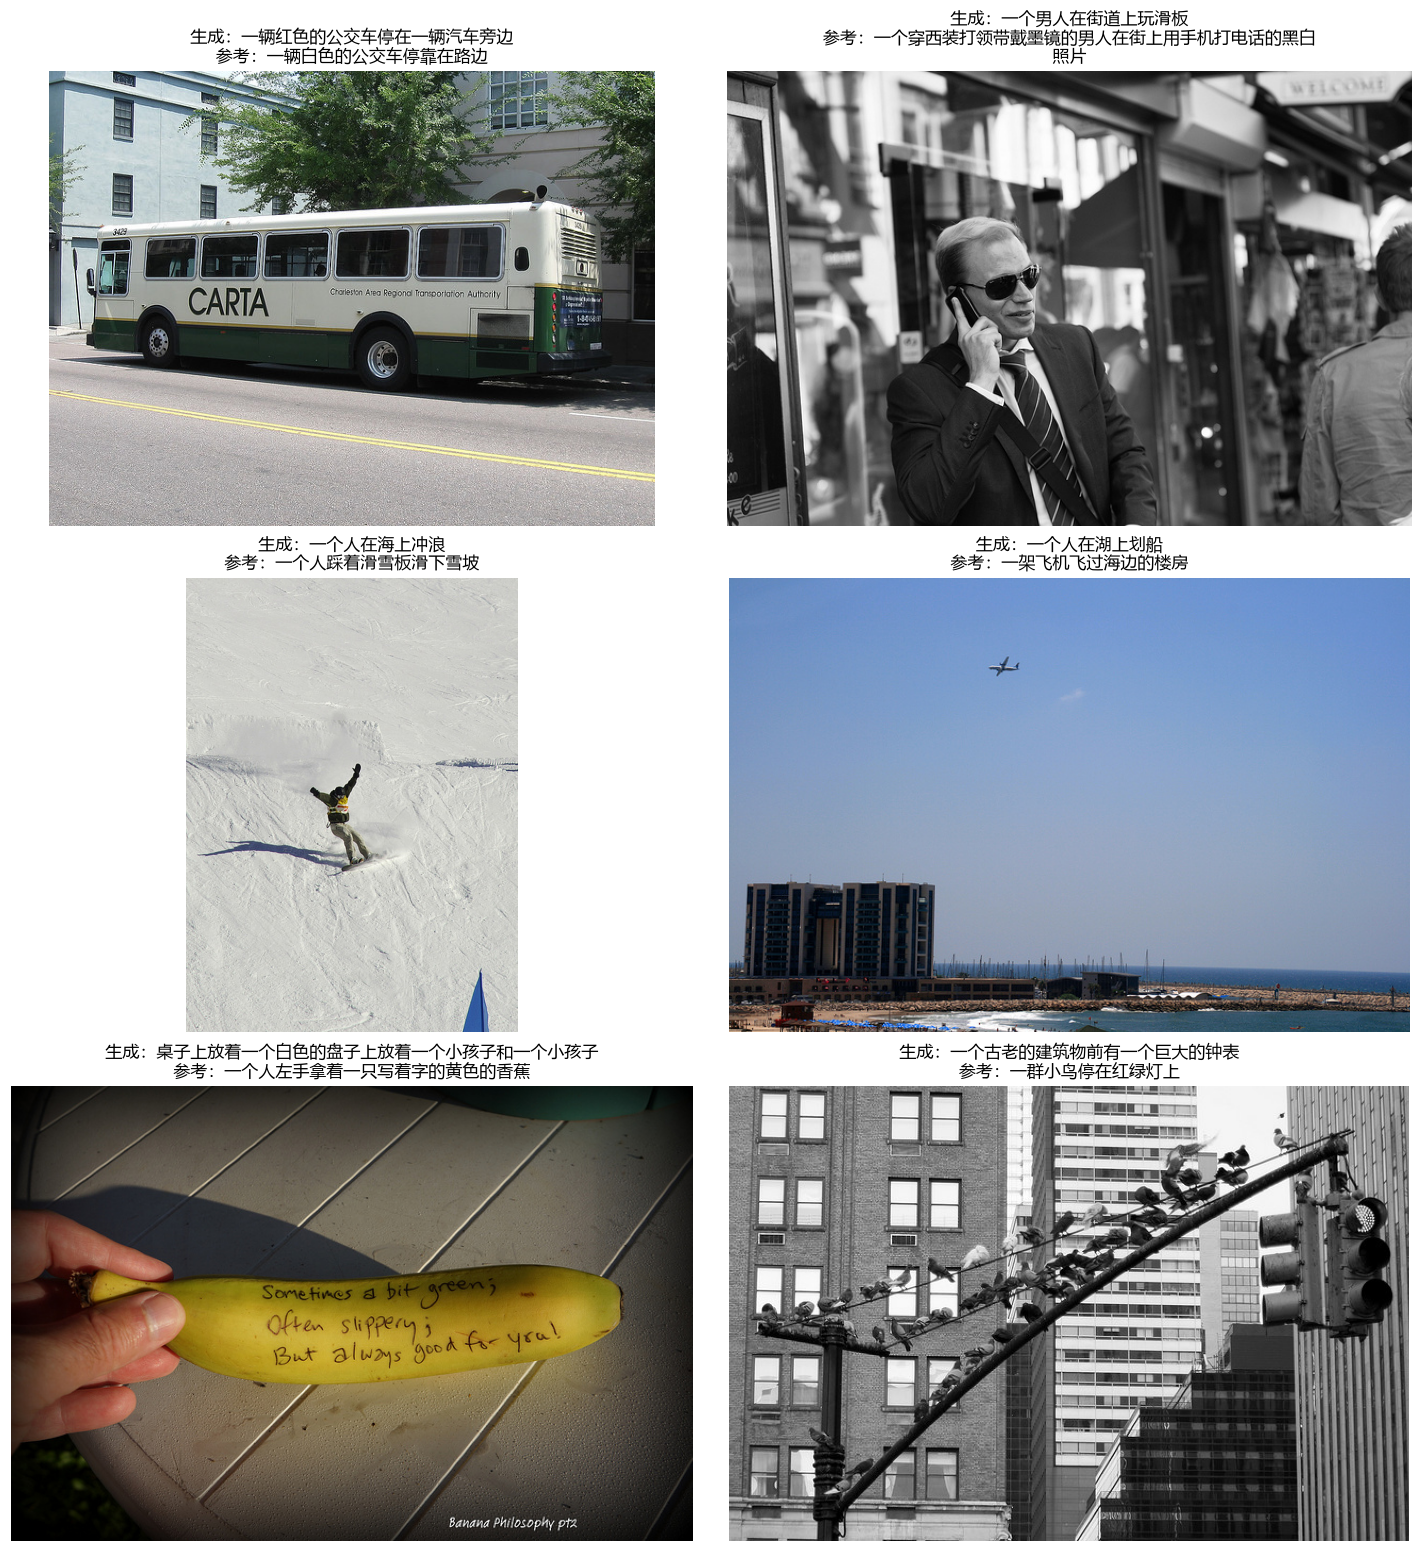

In [6]:
import textwrap
# 固定展示测试清单前六张，保留重复、错误和不流畅的生成结果。
fig,axes=plt.subplots(3,2,figsize=(13,14),constrained_layout=True)
for j,ax in enumerate(axes.flat):
    key=predictions.iloc[j].image_id
    with Image.open(DATA/"coco_cn/images"/(key+".jpg")) as im:ax.imshow(im.convert("RGB"))
    ax.axis("off")
    title="生成："+generated[j]+"\n参考："+test_refs[j][0]
    ax.set_title("\n".join(textwrap.fill(line,width=29) for line in title.splitlines()),fontsize=11)
fig.savefig(RESULT/"caption_examples.png",dpi=180);plt.show()
for j in range(6):
    key=predictions.iloc[j].image_id
    fig,ax=plt.subplots(figsize=(6,5),constrained_layout=True)
    with Image.open(DATA/"coco_cn/images"/(key+".jpg")) as im:ax.imshow(im.convert("RGB"))
    ax.axis("off")
    ax.set_title(textwrap.fill("生成："+generated[j],28)+"\n"+textwrap.fill("参考："+test_refs[j][0],28),fontsize=10)
    fig.savefig(RESULT/f"example_{j+1}.png",dpi=180);plt.close(fig)

## 分析依据与限制

结合实际样例分析主体、动作、数量、场景是否与图像一致，是否重复或提前结束，并比较正确/错配图像的指标差异。损失下降只证明参考前文条件下的拟合，不等于自由生成时语义正确。字符级 n gram 指标会奖励常见字词，不足以衡量视觉语义。样例直接展示测试清单前六张，不据此推断所有图像的质量。

本实验只用官方数据的 CPU 子集，冻结编码器，不含注意力或大规模预训练语言模型。全局 512 维特征难以保留目标空间关系；teacher forcing 有训练与生成分布差异，可能生成常见但错误的句式。结果应按真实输出陈述，不能当成完整 COCO CN 数据集的基准成绩。代码截图可截取 CaptionDecoder 和训练单元格。

实际 300 张测试图上的字符级 BLEU1 为 0.3055、BLEU4 为 0.0849、ROUGE L 为 0.3016；错配图像后 BLEU4 和 ROUGE L 分别降至 0.0262、0.1802。贪心生成共出现 121 种不同句子。固定前六张样例中，公交车主体被识别出来但颜色错误，打电话被描述为玩滑板，滑雪被描述为冲浪，还出现重复词句，说明视觉语义与生成流畅性仍有明显不足。验证最低损失出现在第 17 轮，此后训练损失继续下降而验证不再改善。